# Introduction

This code was developed for my Master’s thesis investigating the impact of macroeconomic variables on short-term rental (Airbnb) supply across European capital cities. Using a balanced panel dataset (August 2020 - December 2024), the project evaluates how economic conditions affect Airbnb listing growth and adds analysis across different property types (entire homes, private rooms, and shared rooms).

# Table of Contents
- [Load and Inspect](#load-and-inspect-dataset)
- [Plots](#plots) - Inspects relationship in the data
- [Models](#models) - OLS, FE, RE, Hausman test
- [Fixed Effects-Two Stage Least Squares](#fe-2sls) - Instrumented model and aggregated by listing types
- [Diagnostic Tests](#testing) - Autocorrelation, Heteroskedasticity, Non-Normality?
- [Hypotheses and Results](#hypotheses-vs-fe-2sls-results-total-listings)

# Load and inspect dataset

In [ ]:
library(readxl)
library(dplyr)
library(ggplot2)
library(plm)
library(fixest)
library(ivreg)
library(AER)
library(lmtest)
library(car)
library(tseries)
library(urca)
library(forecast)
library(stargazer)
library(corrplot)

#setwd("/Users/user/Downloads")


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'plm'


The following objects are masked from 'package:dplyr':

    between, lag, lead


Loading required package: car

Loading required package: carData


Attaching package: 'car'


The following object is masked from 'package:dplyr':

    recode


Loading required package: lmtest

Loading required package: zoo


Attaching package: 'zoo'


The following objects are masked from 'package:base':

    as.Date, as.Date.numeric


Loading required package: sandwich

Loading required package: survival

Registered S3 methods overwritten by 'AER':
  method              from 
  print.ivreg         ivreg
  print.summary.ivreg ivreg
  summary.ivreg       ivreg
  vcov.ivreg          ivreg
  bread.ivreg         ivreg
  estfun.ivreg        ivreg
  hatvalues.ivreg     ivreg
  predict.

In [ ]:
#write.csv(as.data.frame(pdata), "Data.csv", row.names = FALSE, na = "")

In [2]:
pdata <- read.csv("Data.csv")
pdata$date <- as.Date(pdata$date)

In [3]:
pdata <- pdata.frame(pdata, index = c("country", "date"))

In [4]:
summary(pdata)

     country             date            m               y       
 Austria :  53   2020-08-01:  27   Min.   : 1.00   Min.   :2020  
 Belgium :  53   2020-09-01:  27   1st Qu.: 4.00   1st Qu.:2021  
 Bulgaria:  53   2020-10-01:  27   Median : 7.00   Median :2022  
 Croatia :  53   2020-11-01:  27   Mean   : 6.83   Mean   :2022  
 Cyprus  :  53   2020-12-01:  27   3rd Qu.:10.00   3rd Qu.:2023  
 Czechia :  53   2021-01-01:  27   Max.   :12.00   Max.   :2024  
 (Other) :1113   (Other)   :1269                                 
     qtr            semi_annual        ln_listings_total ln_entire_place 
 Length:1431        Length:1431        Min.   : 5.081    Min.   : 4.736  
 Class :character   Class :character   1st Qu.: 7.156    1st Qu.: 6.976  
 Mode  :character   Mode  :character   Median : 7.910    Median : 7.738  
                                       Mean   : 8.006    Mean   : 7.810  
                                       3rd Qu.: 8.923    3rd Qu.: 8.728  
                            

In [50]:
# latex table exclusion
used_cols <- c("d_ln_listings_total", "d_ln_listings_entire", "d_ln_listings_private", "d_ln_listings_shared",
                "gdp_gap", "unemp", "yoy_wages",
                "yoy_hpi", "yoy_housing_costs", "yoy_electricity",
                "d_cci", "d_interest_rate", "eurozone_dummy",
                "d_ln_arrivals", "d_shift_share"
            )
data_subset <- pdata[, used_cols]

stargazer(data_subset, 
          type = "latex", 
          title = "Descriptive Statistics of pdata", 
          header = FALSE, 
          digits = 2)


\begin{table}[!htbp] \centering 
  \caption{Descriptive Statistics of pdata} 
  \label{} 
\begin{tabular}{@{\extracolsep{5pt}}lccccc} 
\\[-1.8ex]\hline 
\hline \\[-1.8ex] 
Statistic & \multicolumn{1}{c}{N} & \multicolumn{1}{c}{Mean} & \multicolumn{1}{c}{St. Dev.} & \multicolumn{1}{c}{Min} & \multicolumn{1}{c}{Max} \\ 
\hline \\[-1.8ex] 
d\_ln\_listings\_total & 1,431 & 0.02 & 0.11 & $-$1.20 & 1.20 \\ 
d\_ln\_listings\_entire & 1,431 & 0.02 & 0.15 & $-$2.24 & 2.36 \\ 
d\_ln\_listings\_private & 1,431 & 0.02 & 0.10 & $-$0.30 & 0.77 \\ 
d\_ln\_listings\_shared & 1,431 & 0.02 & 0.18 & $-$1.13 & 1.79 \\ 
gdp\_gap & 1,431 & 0.02 & 2.44 & $-$20.28 & 15.25 \\ 
unemp & 1,431 & 6.12 & 2.60 & 2.10 & 17.80 \\ 
yoy\_wages & 1,431 & 0.06 & 0.04 & $-$0.07 & 0.22 \\ 
yoy\_hpi & 1,431 & 0.07 & 0.07 & $-$0.15 & 0.28 \\ 
yoy\_housing\_costs & 1,431 & 0.06 & 0.12 & $-$0.51 & 0.91 \\ 
yoy\_electricity & 1,431 & 0.13 & 0.90 & $-$0.86 & 20.59 \\ 
d\_cci & 1,431 & 0.01 & 3.54 & $-$19.50 & 16.50 \\ 
d\_intere

In [31]:
# ls()       # list files
# rm()      # remove
# na.omit(pdata)

### Outliers

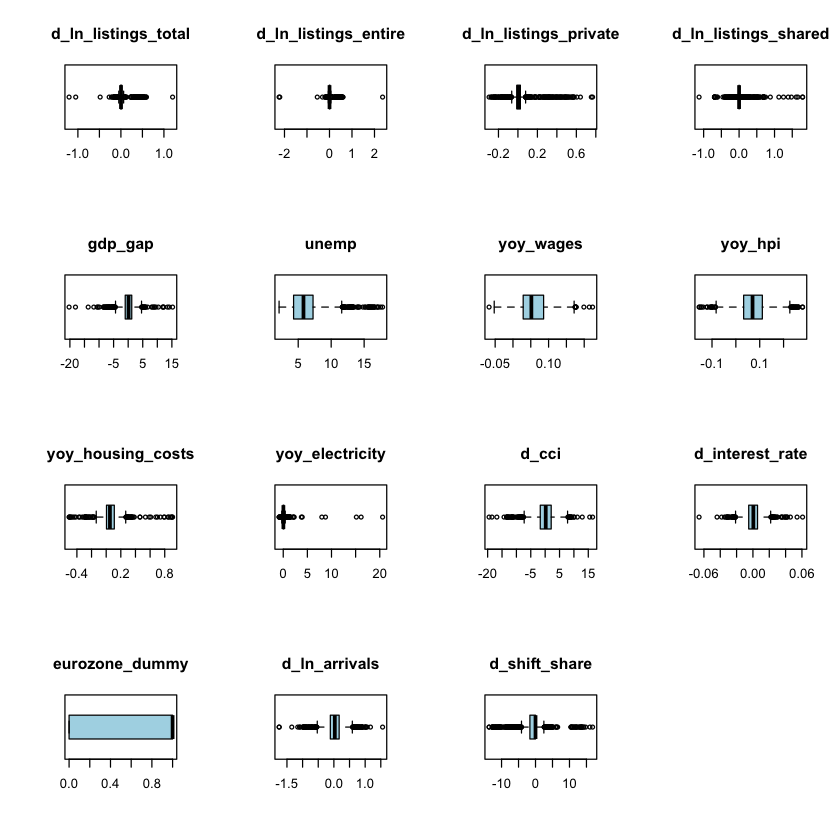

In [51]:
par(mfrow = c(4, 4))    # order the graphs

# Boxplots
for (v in used_cols) {
  boxplot(pdata[[v]], main = v, col = "lightblue", horizontal = TRUE)}

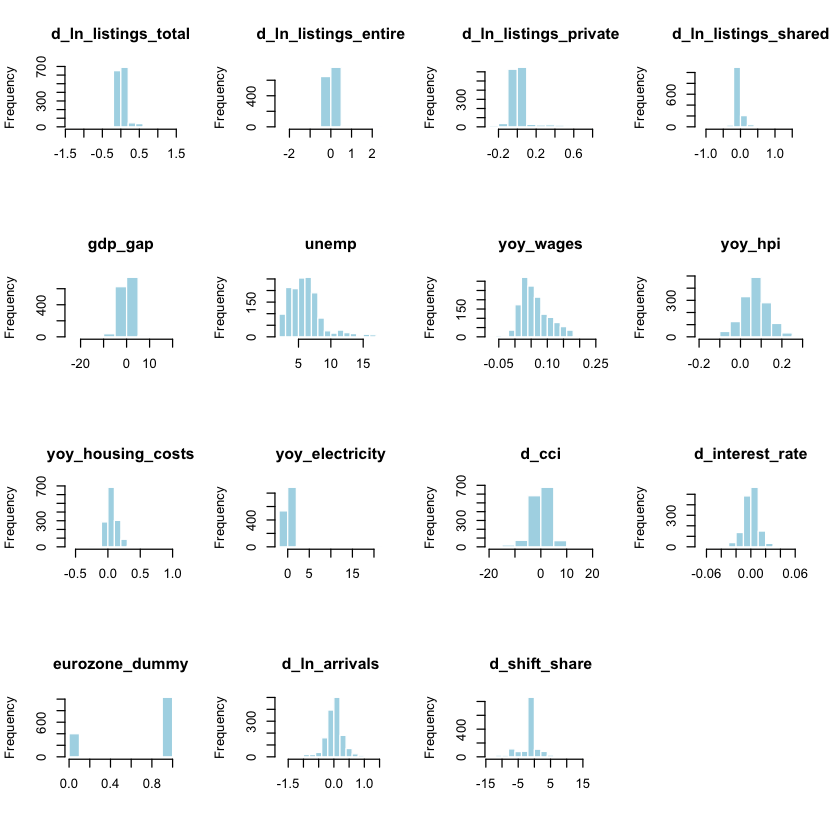

In [52]:
par(mfrow = c(4, 4))    # order the graphs

# Histograms
for (v in used_cols) {
  hist(pdata[[v]], main = v, col = "lightblue", xlab = "", border = "white")}

### Plots

In [6]:
plot_data <- tibble(
  country = as.character(pdata$country),
  
  d_ln_listings_total = as.numeric(pdata$d_ln_listings_total),
  d_ln_listings_entire = as.numeric(pdata$d_ln_listings_entire),
  d_ln_listings_private = as.numeric(pdata$d_ln_listings_private),
  d_ln_listings_shared = as.numeric(pdata$d_ln_listings_shared),


  gdp_gap = as.numeric(pdata$gdp_gap),

  unemp = as.numeric(pdata$unemp),
  yoy_wages = as.numeric(pdata$yoy_wages),

  yoy_hpi = as.numeric(pdata$yoy_hpi),
  yoy_housing_costs = as.numeric(pdata$yoy_housing_costs),
  yoy_electricity = as.numeric(pdata$yoy_electricity),

  d_interest_rate = as.numeric(pdata$d_interest_rate),
  eurozone_dummy = as.numeric(pdata$eurozone_dummy),

  cci = as.numeric(pdata$cci),
  d_cci = as.numeric(pdata$d_cci),

  d_ln_arrivals = as.numeric(pdata$d_ln_arrivals),
  d_shift_share = as.numeric(pdata$d_shift_share))

In [7]:
sapply(plot_data, class)

country   d_ln_listings_total  d_ln_listings_entire 
          "character"             "numeric"             "numeric" 
d_ln_listings_private  d_ln_listings_shared               gdp_gap 
            "numeric"             "numeric"             "numeric" 
                unemp             yoy_wages               yoy_hpi 
            "numeric"             "numeric"             "numeric" 
    yoy_housing_costs       yoy_electricity       d_interest_rate 
            "numeric"             "numeric"             "numeric" 
       eurozone_dummy                   cci                 d_cci 
            "numeric"             "numeric"             "numeric" 
        d_ln_arrivals         d_shift_share 
            "numeric"             "numeric"

#### With differenced ln listings

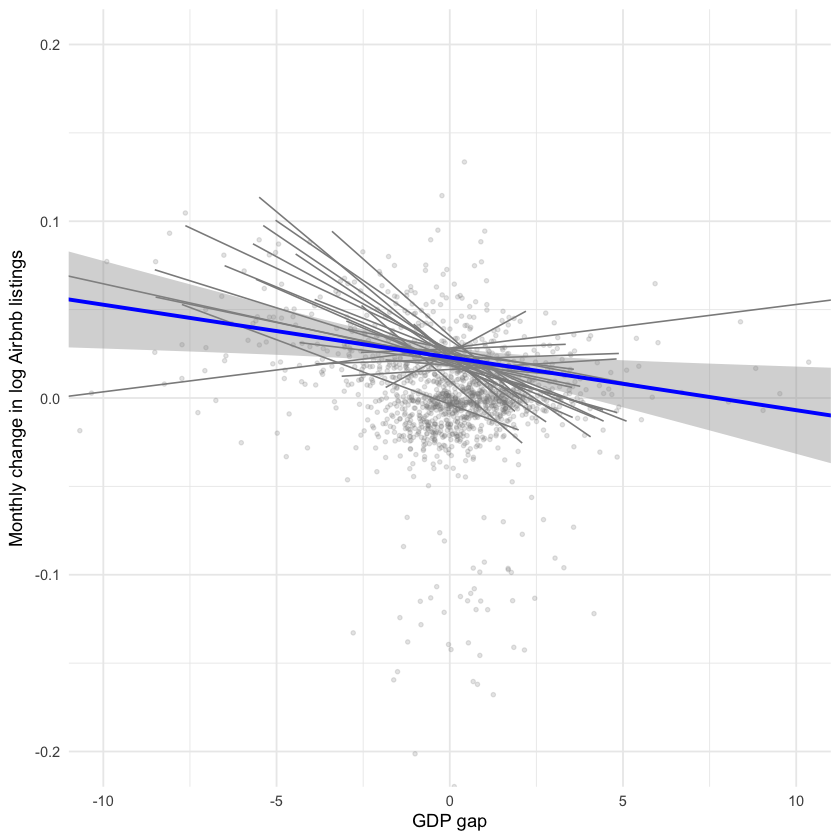

In [ ]:
# GDP gap
ggplot(
  plot_data %>%
    filter(
      is.finite(gdp_gap),
      is.finite(d_ln_listings_total)),
  aes(
    x = gdp_gap,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-10, 10),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "GDP gap",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

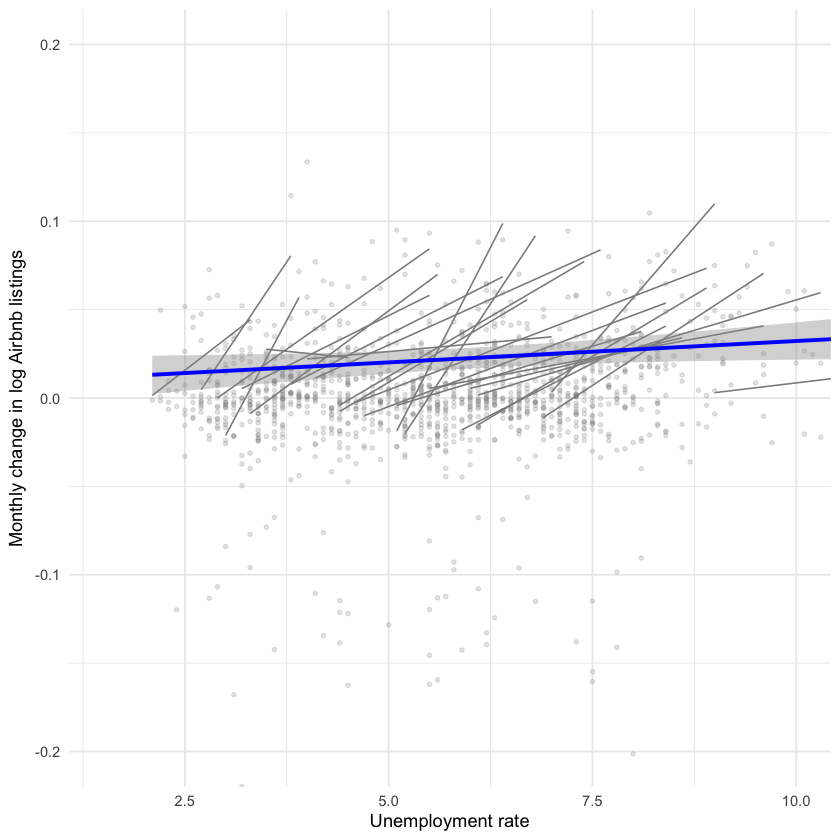

In [ ]:
# unemployment
ggplot(
  plot_data %>%
    filter(
      is.finite(unemp),
      is.finite(d_ln_listings_total)),
  aes(
    x = unemp,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(1.5, 10),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Unemployment rate",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

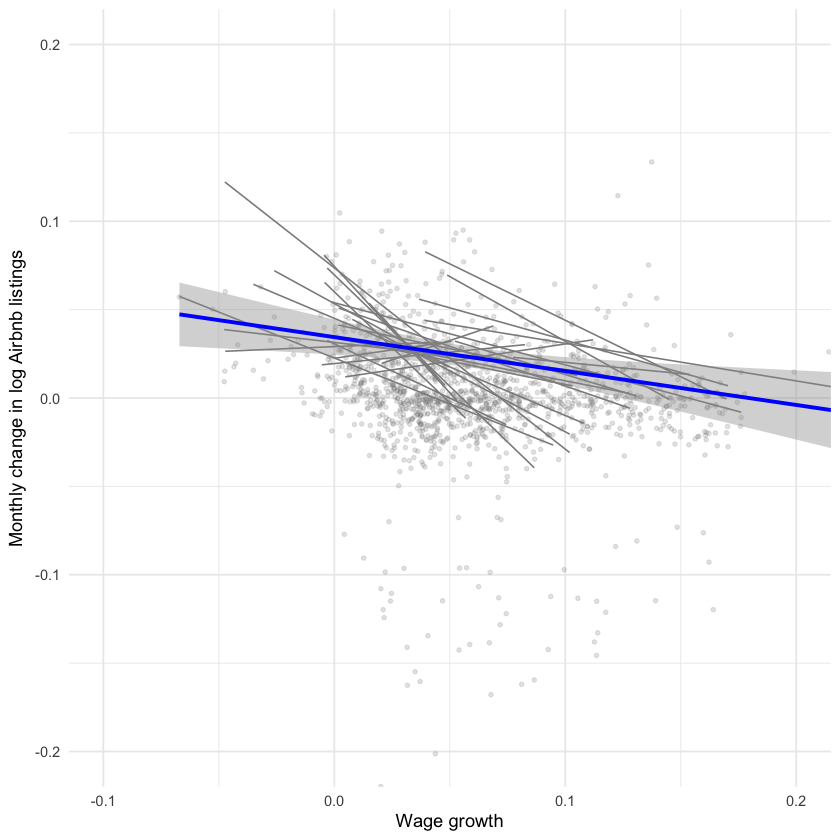

In [18]:
# wage growth
ggplot(
  plot_data %>%
    filter(
      is.finite(yoy_wages),
      is.finite(d_ln_listings_total)),
  aes(
    x = yoy_wages,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-0.1, 0.2),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Wage growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

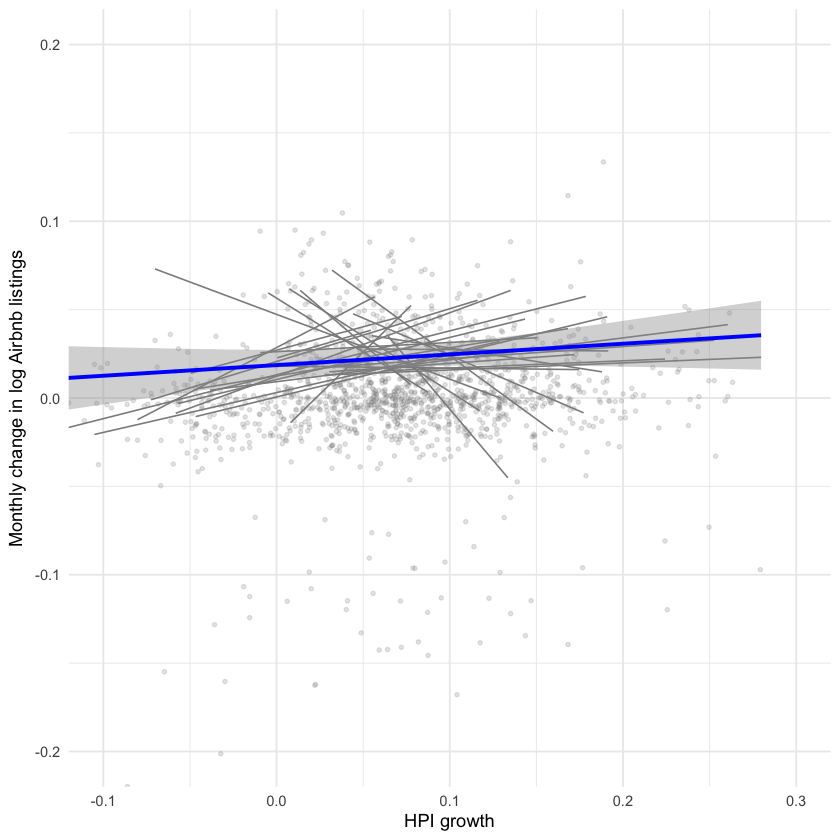

In [ ]:
# HPI growth
ggplot(
  plot_data %>%
    filter(
      is.finite(yoy_hpi),
      is.finite(d_ln_listings_total)),
  aes(
    x = yoy_hpi,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-0.1, 0.3),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "HPI growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

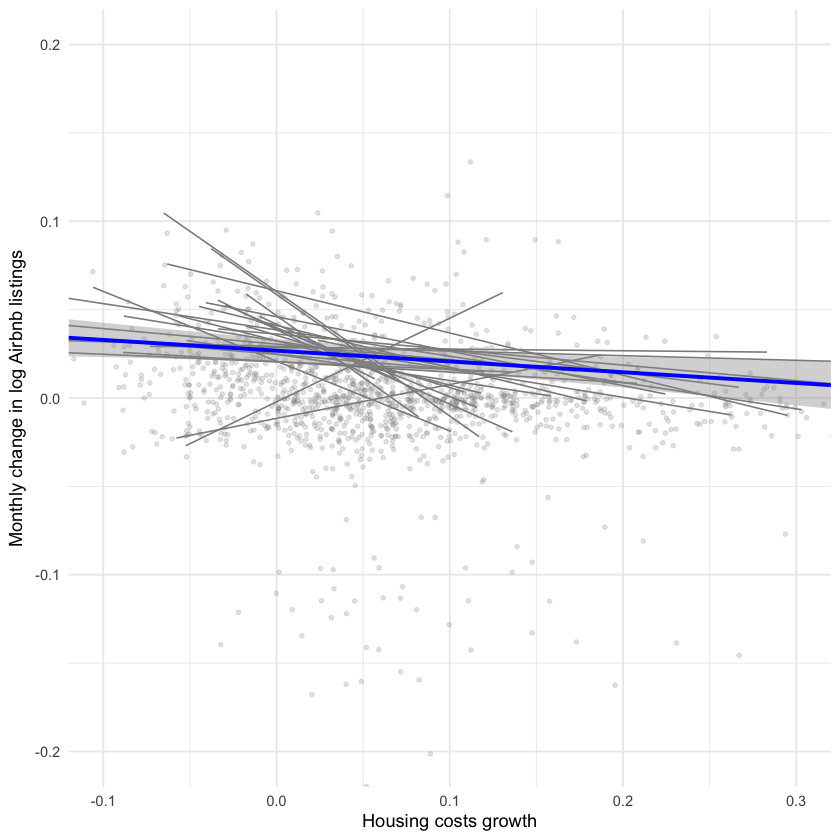

In [22]:
# housing costs growth
ggplot(
  plot_data %>%
    filter(
      is.finite(yoy_housing_costs),
      is.finite(d_ln_listings_total)),
  aes(
    x = yoy_housing_costs,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-0.1, 0.3),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Housing costs growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

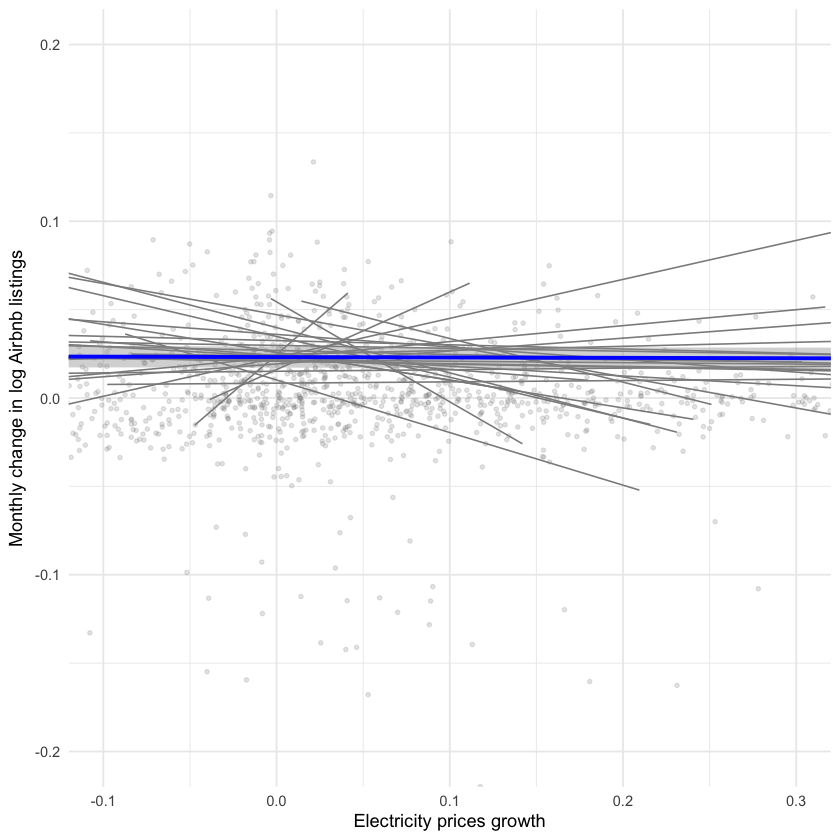

In [24]:
# electricity prices growth
ggplot(
  plot_data %>%
    filter(
      is.finite(yoy_electricity),
      is.finite(d_ln_listings_total)),
  aes(
    x = yoy_electricity,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-0.1, 0.3),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Electricity prices growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

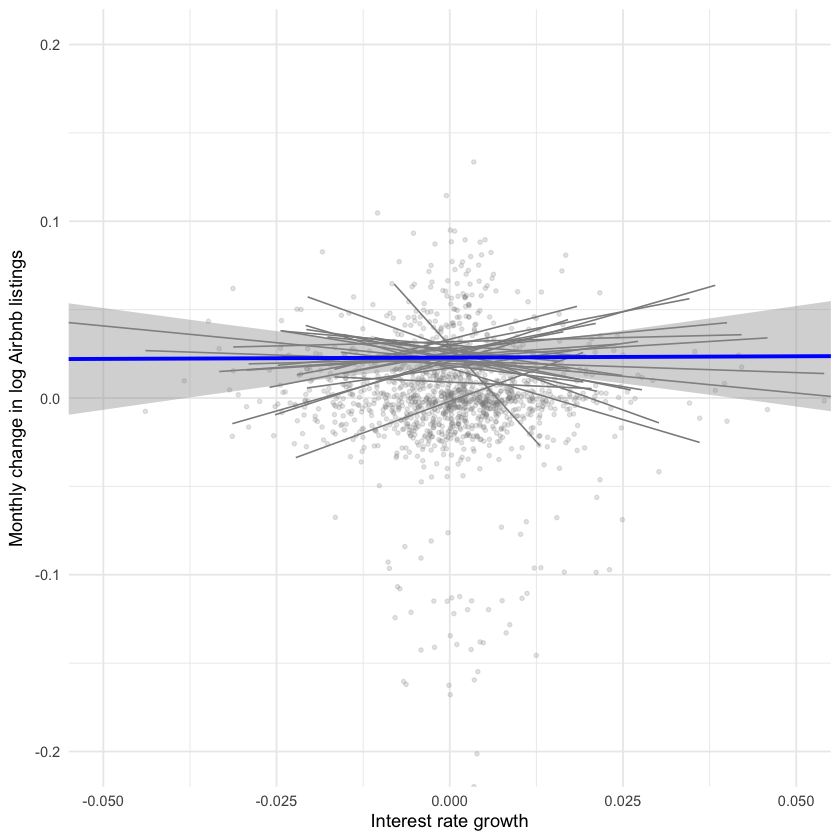

In [28]:
# interest rate growth
ggplot(
  plot_data %>%
    filter(
      is.finite(d_interest_rate),
      is.finite(d_ln_listings_total)),
  aes(
    x = d_interest_rate,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-0.05, 0.05),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Interest rate growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

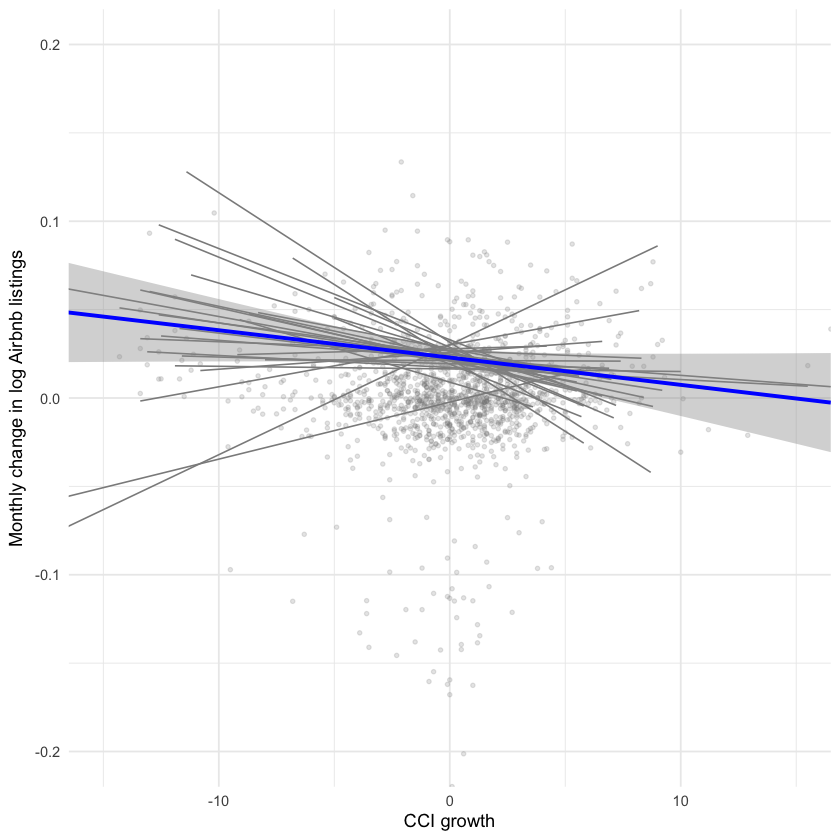

In [32]:
# CCI growth
ggplot(
  plot_data %>%
    filter(
      is.finite(d_cci),
      is.finite(d_ln_listings_total)),
  aes(
    x = d_cci,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-15, 15),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "CCI growth",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

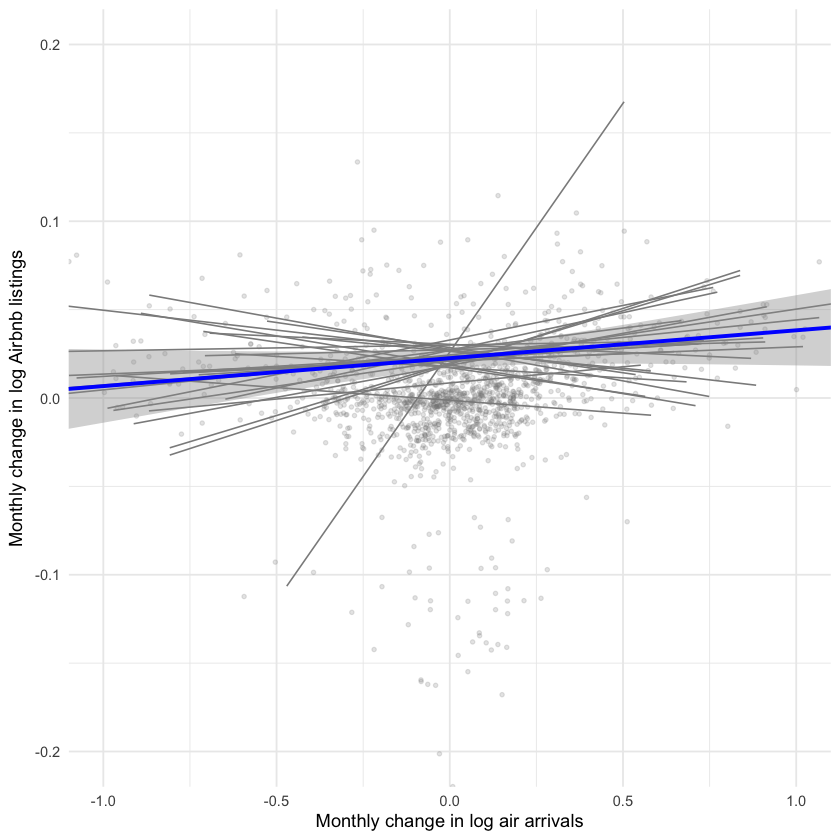

In [ ]:
# Air arrivals growth
ggplot(
  plot_data %>%
    filter(
      is.finite(d_ln_arrivals),
      is.finite(d_ln_listings_total)),
  aes(
    x = d_ln_arrivals,
    y = d_ln_listings_total)) +
  geom_point(
    alpha = 0.2,
    size = 0.9,
    colour = "grey50") +
  geom_smooth(
    aes(group = country),
    method = "lm",
    formula = y ~ x,
    se = FALSE,
    linewidth = 0.45,
    alpha = 0.45,
    colour = "grey55") +
  geom_smooth(
    method = "lm",
    formula = y ~ x,
    se = TRUE,
    linewidth = 1.1,
    colour = "blue") +
  coord_cartesian(
    xlim = c(-1, 1),
    ylim = c(-0.2, 0.2)) +
  labs(
    x = "Monthly change in log air arrivals",
    y = "Monthly change in log Airbnb listings",) +
  theme_minimal()

### Stationarity and Unit Root Tests

In [54]:
purtest(pdata$d_ln_listings_total, test = "ips", exo = "intercept")

purtest(pdata$d_ln_listings_entire, test = "ips", exo = "intercept")

purtest(pdata$d_ln_listings_private, test = "ips", exo = "intercept")

purtest(pdata$d_ln_listings_shared, test = "ips", exo = "intercept")


	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_ln_listings_total
Wtbar = -35.557, p-value < 2.2e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_ln_listings_entire
Wtbar = -35.985, p-value < 2.2e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_ln_listings_private
Wtbar = -35.652, p-value < 2.2e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_ln_listings_shared
Wtbar = -36.144, p-value < 2.2e-16
alternative hypothesis: stationarity


In [55]:
purtest(pdata$gdp_gap, test = "ips", exo = "intercept")

purtest(pdata$unemp, test = "ips", exo = "intercept")

purtest(pdata$yoy_wages, test = "ips", exo = "intercept")


	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$gdp_gap
Wtbar = -7.9634, p-value = 8.371e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$unemp
Wtbar = -3.7764, p-value = 7.956e-05
alternative hypothesis: stationarity


Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"
Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"
Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"
Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$yoy_wages
Wtbar = -4.8811, p-value = 5.274e-07
alternative hypothesis: stationarity


In [56]:
purtest(pdata$yoy_hpi, test = "ips", exo = "intercept")

purtest(pdata$yoy_housing_costs, test = "ips", exo = "intercept")

purtest(pdata$yoy_electricity, test = "ips", exo = "intercept")

purtest(pdata$d_cci, test = "ips", exo = "intercept")


	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$yoy_hpi
Wtbar = -6.101, p-value = 5.271e-10
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$yoy_housing_costs
Wtbar = -7.9802, p-value = 7.306e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$yoy_electricity
Wtbar = -5.0134, p-value = 2.674e-07
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_cci
Wtbar = -36.642, p-value < 2.2e-16
alternative hypothesis: stationarity


In [57]:
purtest(pdata$d_interest_rate, test = "ips", exo = "intercept")

purtest(pdata$d_ln_arrivals, test = "ips", exo = "intercept")

purtest(pdata$d_shift_share, test = "ips", exo = "intercept")

Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_interest_rate
Wtbar = -45.714, p-value < 2.2e-16
alternative hypothesis: stationarity


Warning message in adj.ips.wtbar.value(x, y, exo = exo):
"lags should be an integer between 0 and 8"



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_ln_arrivals
Wtbar = -21.336, p-value < 2.2e-16
alternative hypothesis: stationarity



	Im-Pesaran-Shin Unit-Root Test (ex. var.: Individual Intercepts)

data:  pdata$d_shift_share
Wtbar = -15.998, p-value < 2.2e-16
alternative hypothesis: stationarity


* smaller than 0.05 then we reject null, thus its stationary
* all above is stationary

### Correlation Matrix

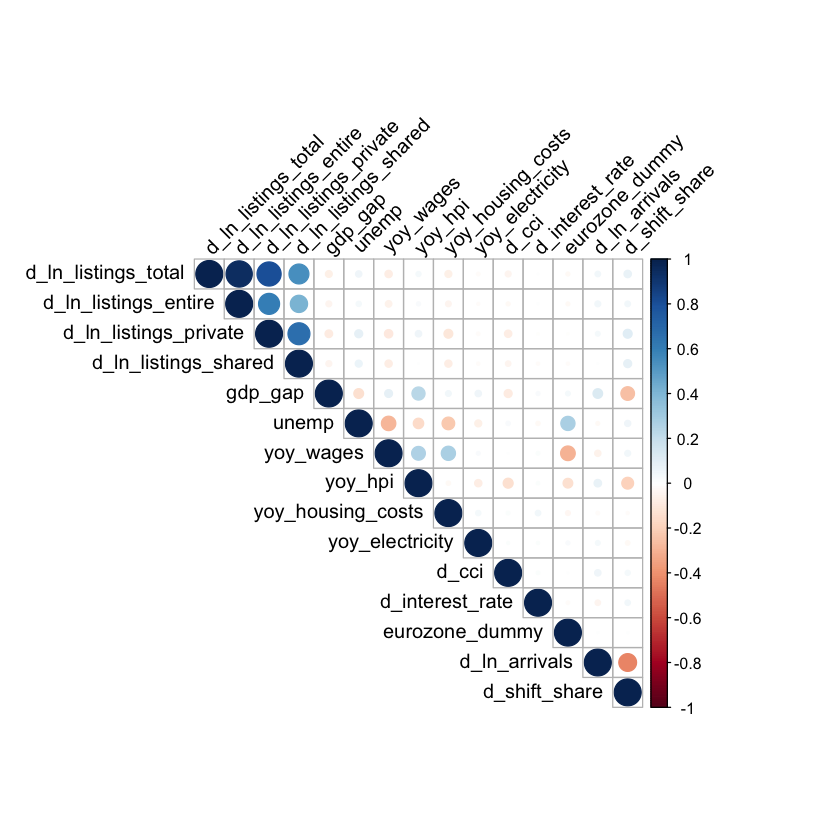

In [58]:
cor_matrix <- cor(data_subset, use = "complete.obs")
corrplot(cor_matrix, method = "circle", type = "upper", tl.col = "black", tl.srt = 45)

# Models

## OLS

In [9]:
ols_model <- lm(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
            data = pdata)

summary(ols_model)
vif(ols_model)
AIC(ols_model)


Call:
lm(formula = d_ln_listings_total ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.23574 -0.03197 -0.01640 -0.00148  1.14828 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)        0.0259977  0.0115519   2.251  0.02457 * 
gdp_gap           -0.0034563  0.0012799  -2.700  0.00701 **
unemp              0.0018043  0.0012558   1.437  0.15101   
yoy_wages         -0.1919686  0.0777825  -2.468  0.01370 * 
yoy_hpi            0.1046899  0.0491010   2.132  0.03317 * 
yoy_housing_costs -0.0288781  0.0255889  -1.129  0.25928   
yoy_electricity   -0.0004728  0.0033214  -0.142  0.88681   
d_cci             -0.0015785  0.0008547  -1.847  0.06499 . 
d_interest_rate    0.0848054  0.2838792   0.299  0.76518   
eurozone_dummy    -0.0116294  0.0071692  -1.622  0.10500   
d_ln_arrivals      

gdp_gap             unemp         yoy_wages           yoy_hpi 
         1.104896          1.204928          1.314355          1.191974 
yoy_housing_costs   yoy_electricity             d_cci   d_interest_rate 
         1.138236          1.019579          1.031547          1.005277 
   eurozone_dummy     d_ln_arrivals 
         1.169545          1.035856

[1] -2177.942

In [11]:
# entire place
ols_model <- lm(d_ln_listings_entire ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
            data = pdata)

summary(ols_model)
vif(ols_model)
AIC(ols_model)


Call:
lm(formula = d_ln_listings_entire ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.26717 -0.03106 -0.01707 -0.00268  2.30504 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)  
(Intercept)        0.0287521  0.0148657   1.934   0.0533 .
gdp_gap           -0.0032716  0.0016471  -1.986   0.0472 *
unemp              0.0015708  0.0016161   0.972   0.3312  
yoy_wages         -0.2053439  0.1000950  -2.051   0.0404 *
yoy_hpi            0.0952927  0.0631859   1.508   0.1317  
yoy_housing_costs -0.0205974  0.0329293  -0.626   0.5317  
yoy_electricity   -0.0004924  0.0042742  -0.115   0.9083  
d_cci             -0.0009910  0.0010999  -0.901   0.3677  
d_interest_rate    0.1322214  0.3653118   0.362   0.7174  
eurozone_dummy    -0.0128450  0.0092258  -1.392   0.1641  
d_ln_arrivals      0.0236021 

gdp_gap             unemp         yoy_wages           yoy_hpi 
         1.104896          1.204928          1.314355          1.191974 
yoy_housing_costs   yoy_electricity             d_cci   d_interest_rate 
         1.138236          1.019579          1.031547          1.005277 
   eurozone_dummy     d_ln_arrivals 
         1.169545          1.035856

[1] -1456.138

In [12]:
# private room
ols_model <- lm(d_ln_listings_private ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
            data = pdata)

summary(ols_model)
vif(ols_model)
AIC(ols_model)


Call:
lm(formula = d_ln_listings_private ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.29338 -0.03462 -0.01531  0.00595  0.71332 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)        0.0171916  0.0104682   1.642 0.100755    
gdp_gap           -0.0039917  0.0011599  -3.442 0.000595 ***
unemp              0.0025198  0.0011380   2.214 0.026973 *  
yoy_wages         -0.2039166  0.0704854  -2.893 0.003874 ** 
yoy_hpi            0.1454332  0.0444945   3.269 0.001107 ** 
yoy_housing_costs -0.0519057  0.0231883  -2.238 0.025347 *  
yoy_electricity    0.0005043  0.0030098   0.168 0.866948    
d_cci             -0.0021217  0.0007746  -2.739 0.006235 ** 
d_interest_rate    0.0177865  0.2572470   0.069 0.944886    
eurozone_dummy    -0.0083228  0.0064967  -1.281 0.200373    
d_ln_a

gdp_gap             unemp         yoy_wages           yoy_hpi 
         1.104896          1.204928          1.314355          1.191974 
yoy_housing_costs   yoy_electricity             d_cci   d_interest_rate 
         1.138236          1.019579          1.031547          1.005277 
   eurozone_dummy     d_ln_arrivals 
         1.169545          1.035856

[1] -2459.883

In [13]:
# shared room
ols_model <- lm(d_ln_listings_shared ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
            data = pdata)

summary(ols_model)
vif(ols_model)
AIC(ols_model)


Call:
lm(formula = d_ln_listings_shared ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.12355 -0.03886 -0.01635  0.00584  1.78645 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)  
(Intercept)        0.0247273  0.0181990   1.359   0.1745  
gdp_gap           -0.0030779  0.0020164  -1.526   0.1271  
unemp              0.0035397  0.0019785   1.789   0.0738 .
yoy_wages         -0.2505533  0.1225389  -2.045   0.0411 *
yoy_hpi            0.0603390  0.0773538   0.780   0.4355  
yoy_housing_costs -0.0576777  0.0403129  -1.431   0.1527  
yoy_electricity   -0.0005906  0.0052325  -0.113   0.9101  
d_cci             -0.0021114  0.0013466  -1.568   0.1171  
d_interest_rate   -0.1536304  0.4472244  -0.344   0.7313  
eurozone_dummy    -0.0172889  0.0112945  -1.531   0.1261  
d_ln_arrivals      0.0031434 

gdp_gap             unemp         yoy_wages           yoy_hpi 
         1.104896          1.204928          1.314355          1.191974 
yoy_housing_costs   yoy_electricity             d_cci   d_interest_rate 
         1.138236          1.019579          1.031547          1.005277 
   eurozone_dummy     d_ln_arrivals 
         1.169545          1.035856

[1] -877.1291

## FE

In [14]:
# fe - using plm to compare with re
fixed_model_plm <- plm(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
                   data = pdata, model = "within")

summary(fixed_model_plm)

coeftest(fixed_model_plm, vcov = vcovHC(fixed_model_plm, method = "arellano", type = "HC1", cluster = "group"))

Oneway (individual) effect Within Model

Call:
plm(formula = d_ln_listings_total ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata, model = "within")

Balanced Panel: n = 27, T = 53, N = 1431

Residuals:
       Min.     1st Qu.      Median     3rd Qu.        Max. 
-1.20488763 -0.03237074 -0.01704295 -0.00045053  1.12964477 

Coefficients:
                     Estimate  Std. Error t-value Pr(>|t|)   
gdp_gap           -0.00238936  0.00137222 -1.7412 0.081864 . 
unemp              0.01281880  0.00392944  3.2622 0.001132 **
yoy_wages         -0.21890372  0.12086684 -1.8111 0.070338 . 
yoy_hpi            0.13667104  0.06023518  2.2690 0.023423 * 
yoy_housing_costs -0.02706513  0.02741940 -0.9871 0.323775   
yoy_electricity    0.00029139  0.00347486  0.0839 0.933183   
d_cci             -0.00163101  0.00086086 -1.8946 0.058351 . 
d_interest_rate    0.11889181  0.28497757  0.4172 0.


t test of coefficients:

                     Estimate  Std. Error t value  Pr(>|t|)    
gdp_gap           -0.00238936  0.00220916 -1.0816 0.2796329    
unemp              0.01281880  0.00409836  3.1278 0.0017977 ** 
yoy_wages         -0.21890372  0.08215097 -2.6647 0.0077957 ** 
yoy_hpi            0.13667104  0.03947602  3.4621 0.0005521 ***
yoy_housing_costs -0.02706513  0.01528390 -1.7708 0.0768081 .  
yoy_electricity    0.00029139  0.00103551  0.2814 0.7784492    
d_cci             -0.00163101  0.00054685 -2.9825 0.0029083 ** 
d_interest_rate    0.11889181  0.15754083  0.7547 0.4505727    
eurozone_dummy     0.01908395  0.00874959  2.1811 0.0293409 *  
d_ln_arrivals      0.01622957  0.00729866  2.2236 0.0263327 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


In [15]:
# fe using feols just as when using instrument
fe_model <- feols(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals
  | country, data = pdata, cluster = ~country)

summary(fe_model)

OLS estimation, Dep. Var.: d_ln_listings_total
Observations: 1,431
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value  Pr(>|t|)    
gdp_gap           -0.002389   0.002251 -1.061345 0.2982932    
unemp              0.012819   0.004176  3.069311 0.0049707 ** 
yoy_wages         -0.218904   0.083716 -2.614834 0.0146598 *  
yoy_hpi            0.136671   0.040228  3.397401 0.0021992 ** 
yoy_housing_costs -0.027065   0.015575 -1.737719 0.0940933 .  
yoy_electricity    0.000291   0.001055  0.276134 0.7846281    
d_cci             -0.001631   0.000557 -2.926783 0.0070251 ** 
d_interest_rate    0.118892   0.160542  0.740564 0.4655937    
eurozone_dummy     0.019084   0.008916  2.140347 0.0418772 *  
d_ln_arrivals      0.016230   0.007438  2.182064 0.0383330 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 0.111364     Adj. R2: 0.01025 
                 Within R2: 0.031422

In [16]:
# fe entire - using plm
fixed_model_entire_plm <- plm(d_ln_listings_entire ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
                   data = pdata, model = "within")

summary(fixed_model_entire_plm)
coeftest(fixed_model_entire_plm, vcov = vcovHC(fixed_model_entire_plm, method = "arellano", type = "HC1", cluster = "group"))

Oneway (individual) effect Within Model

Call:
plm(formula = d_ln_listings_entire ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata, model = "within")

Balanced Panel: n = 27, T = 53, N = 1431

Residuals:
       Min.     1st Qu.      Median     3rd Qu.        Max. 
-2.27216078 -0.03269739 -0.01790563 -0.00075192  2.28852571 

Coefficients:
                     Estimate  Std. Error t-value Pr(>|t|)  
gdp_gap           -0.00238789  0.00176866 -1.3501  0.17720  
unemp              0.01114328  0.00506466  2.2002  0.02796 *
yoy_wages         -0.25924676  0.15578552 -1.6641  0.09631 .
yoy_hpi            0.12914964  0.07763725  1.6635  0.09644 .
yoy_housing_costs -0.01832697  0.03534092 -0.5186  0.60414  
yoy_electricity   -0.00014588  0.00447875 -0.0326  0.97402  
d_cci             -0.00101364  0.00110957 -0.9135  0.36111  
d_interest_rate    0.16228633  0.36730817  0.4418  0.65868 


t test of coefficients:

                     Estimate  Std. Error t value Pr(>|t|)   
gdp_gap           -0.00238789  0.00213306 -1.1195 0.263133   
unemp              0.01114328  0.00382391  2.9141 0.003624 **
yoy_wages         -0.25924676  0.09970106 -2.6002 0.009414 **
yoy_hpi            0.12914964  0.04050171  3.1887 0.001461 **
yoy_housing_costs -0.01832697  0.01683488 -1.0886 0.276505   
yoy_electricity   -0.00014588  0.00117796 -0.1238 0.901460   
d_cci             -0.00101364  0.00092238 -1.0989 0.271983   
d_interest_rate    0.16228633  0.18045264  0.8993 0.368633   
eurozone_dummy     0.02108342  0.01039575  2.0281 0.042742 * 
d_ln_arrivals      0.02231531  0.01285135  1.7364 0.082711 . 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


In [17]:
# fe private - using plm
fixed_model_private_plm <- plm(d_ln_listings_private ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
                   data = pdata, model = "within")

summary(fixed_model_private_plm)
coeftest(fixed_model_private_plm, vcov = vcovHC(fixed_model_private_plm, method = "arellano", type = "HC1", cluster = "group"))

Oneway (individual) effect Within Model

Call:
plm(formula = d_ln_listings_private ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata, model = "within")

Balanced Panel: n = 27, T = 53, N = 1431

Residuals:
      Min.    1st Qu.     Median    3rd Qu.       Max. 
-0.2888107 -0.0342851 -0.0152515  0.0079686  0.6932036 

Coefficients:
                     Estimate  Std. Error t-value  Pr(>|t|)    
gdp_gap           -0.00212987  0.00123496 -1.7247  0.084812 .  
unemp              0.01977159  0.00353637  5.5909 2.714e-08 ***
yoy_wages         -0.17881266  0.10877640 -1.6439  0.100432    
yoy_hpi            0.16487427  0.05420979  3.0414  0.002399 ** 
yoy_housing_costs -0.04956682  0.02467661 -2.0087  0.044766 *  
yoy_electricity    0.00213184  0.00312726  0.6817  0.495545    
d_cci             -0.00227041  0.00077475 -2.9305  0.003439 ** 
d_interest_rate    0.06942152  0.25647096  0


t test of coefficients:

                     Estimate  Std. Error t value  Pr(>|t|)    
gdp_gap           -0.00212987  0.00221744 -0.9605  0.336964    
unemp              0.01977159  0.00434365  4.5518 5.781e-06 ***
yoy_wages         -0.17881266  0.10427274 -1.7149  0.086594 .  
yoy_hpi            0.16487427  0.04250974  3.8785  0.000110 ***
yoy_housing_costs -0.04956682  0.01730039 -2.8651  0.004232 ** 
yoy_electricity    0.00213184  0.00093869  2.2711  0.023295 *  
d_cci             -0.00227041  0.00056472 -4.0204 6.121e-05 ***
d_interest_rate    0.06942152  0.18430365  0.3767  0.706477    
eurozone_dummy     0.01563881  0.01130173  1.3838  0.166655    
d_ln_arrivals      0.01099510  0.00612994  1.7937  0.073082 .  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


In [18]:
# fe shared - using plm
fixed_model_shared_plm <- plm(d_ln_listings_shared ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
                   data = pdata, model = "within")

summary(fixed_model_shared_plm)
coeftest(fixed_model_shared_plm, vcov = vcovHC(fixed_model_shared_plm, method = "arellano", type = "HC1", cluster = "group"))

Oneway (individual) effect Within Model

Call:
plm(formula = d_ln_listings_shared ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata, model = "within")

Balanced Panel: n = 27, T = 53, N = 1431

Residuals:
     Min.   1st Qu.    Median   3rd Qu.      Max. 
-1.126522 -0.047044 -0.015983  0.013949  1.733958 

Coefficients:
                     Estimate  Std. Error t-value  Pr(>|t|)    
gdp_gap           -0.00046654  0.00215603 -0.2164 0.8287170    
unemp              0.02277638  0.00617390  3.6891 0.0002337 ***
yoy_wages         -0.36797248  0.18990520 -1.9377 0.0528660 .  
yoy_hpi            0.03681967  0.09464113  0.3890 0.6973022    
yoy_housing_costs -0.06425563  0.04308119 -1.4915 0.1360563    
yoy_electricity    0.00064525  0.00545967  0.1182 0.9059381    
d_cci             -0.00239453  0.00135259 -1.7703 0.0768903 .  
d_interest_rate   -0.08630525  0.44775492 -0.1928 0.847


t test of coefficients:

                     Estimate  Std. Error t value  Pr(>|t|)    
gdp_gap           -0.00046654  0.00239817 -0.1945  0.845782    
unemp              0.02277638  0.00381457  5.9709 2.989e-09 ***
yoy_wages         -0.36797248  0.18953957 -1.9414  0.052411 .  
yoy_hpi            0.03681967  0.07534312  0.4887  0.625136    
yoy_housing_costs -0.06425563  0.04645850 -1.3831  0.166863    
yoy_electricity    0.00064525  0.00145509  0.4434  0.657512    
d_cci             -0.00239453  0.00088773 -2.6974  0.007074 ** 
d_interest_rate   -0.08630525  0.33920652 -0.2544  0.799199    
eurozone_dummy     0.00751293  0.01966694  0.3820  0.702514    
d_ln_arrivals      0.00154794  0.01253474  0.1235  0.901735    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


## RE

In [19]:
# re vars like 2sls
random_model_plm <- plm(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy +
                    d_ln_arrivals,
            data = pdata, model = "random")

summary(random_model_plm)
coeftest(random_model_plm, vcov = vcovHC(random_model_plm, method = "arellano", type = "HC1", cluster = "group"))

Oneway (individual) effect Random Effect Model 
   (Swamy-Arora's transformation)

Call:
plm(formula = d_ln_listings_total ~ gdp_gap + unemp + yoy_wages + 
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci + d_interest_rate + 
    eurozone_dummy + d_ln_arrivals, data = pdata, model = "random")

Balanced Panel: n = 27, T = 53, N = 1431

Effects:
                  var std.dev share
idiosyncratic 0.01273 0.11283     1
individual    0.00000 0.00000     0
theta: 0

Residuals:
      Min.    1st Qu.     Median    3rd Qu.       Max. 
-1.2357434 -0.0319673 -0.0163959 -0.0014791  1.1482802 

Coefficients:
                     Estimate  Std. Error z-value Pr(>|z|)   
(Intercept)        0.02599775  0.01155194  2.2505 0.024417 * 
gdp_gap           -0.00345630  0.00127994 -2.7004 0.006926 **
unemp              0.00180431  0.00125584  1.4367 0.150795   
yoy_wages         -0.19196856  0.07778254 -2.4680 0.013586 * 
yoy_hpi            0.10468987  0.04910096  2.1321 0.032996 * 
yoy_housing_costs


t test of coefficients:

                     Estimate  Std. Error t value  Pr(>|t|)    
(Intercept)        0.02599775  0.00749672  3.4679 0.0005402 ***
gdp_gap           -0.00345630  0.00246788 -1.4005 0.1615783    
unemp              0.00180431  0.00083526  2.1602 0.0309265 *  
yoy_wages         -0.19196856  0.04105139 -4.6763 3.199e-06 ***
yoy_hpi            0.10468987  0.03844583  2.7230 0.0065475 ** 
yoy_housing_costs -0.02887811  0.01521923 -1.8975 0.0579680 .  
yoy_electricity   -0.00047284  0.00106736 -0.4430 0.6578309    
d_cci             -0.00157851  0.00049444 -3.1926 0.0014411 ** 
d_interest_rate    0.08480540  0.16501796  0.5139 0.6073906    
eurozone_dummy    -0.01162945  0.00393313 -2.9568 0.0031600 ** 
d_ln_arrivals      0.01740618  0.00753768  2.3092 0.0210741 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


## Hausman test

If: 
* p value is < 0,05, then we reject null that both fe and re are suitable. FE is consistent.
* p value is > 0,05, then we do not reject null. RE is preferred.

In [44]:
phtest(fixed_model_plm, random_model_plm)


	Hausman Test

data:  d_ln_listings_total ~ gdp_gap + unemp + yoy_wages + yoy_hpi +  ...
chisq = 14.72, df = 10, p-value = 0.1426
alternative hypothesis: one model is inconsistent


## FE-2SLS

In [21]:
iv_model_fe <- feols(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy
            | country
            | d_ln_arrivals ~ d_shift_share,
            data = pdata, cluster = ~country)

summary(iv_model_fe)

TSLS estimation
|- D.V.   : d_ln_listings_total
|- Endo.  : d_ln_arrivals
|- Instr. : d_shift_share
|
|=> Second Stage
|   Dep. Var.: d_ln_listings_total
Observations: 1,431
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value   Pr(>|t|)    
fit_d_ln_arrivals -0.069554   0.018826 -3.694574 1.0315e-03 ** 
gdp_gap           -0.001106   0.001805 -0.612889 5.4527e-01    
unemp              0.012541   0.003605  3.478863 1.7897e-03 ** 
yoy_wages         -0.307814   0.073279 -4.200571 2.7663e-04 ***
yoy_hpi            0.171382   0.037213  4.605422 9.5249e-05 ***
yoy_housing_costs -0.027638   0.011575 -2.387791 2.4506e-02 *  
yoy_electricity    0.001388   0.000973  1.427160 1.6543e-01    
d_cci             -0.001048   0.000549 -1.907271 6.7591e-02 .  
d_interest_rate    0.008981   0.168265  0.053377 9.5784e-01    
eurozone_dummy     0.027686   0.007756  3.569601 1.4207e-03 ** 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 

### Listing types FE-2SLS

In [22]:
iv_model_fe_entire <- feols(d_ln_listings_entire ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy
  | country
  | d_ln_arrivals ~ d_shift_share,
  data = pdata, cluster = ~country)

summary(iv_model_fe_entire)

TSLS estimation
|- D.V.   : d_ln_listings_entire
|- Endo.  : d_ln_arrivals
|- Instr. : d_shift_share
|
|=> Second Stage
|   Dep. Var.: d_ln_listings_entire
Observations: 1,431
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value  Pr(>|t|)    
fit_d_ln_arrivals -0.050763   0.034567 -1.468545 0.1539519    
gdp_gap           -0.001295   0.001850 -0.699992 0.4901489    
unemp              0.010906   0.003357  3.248462 0.0031941 ** 
yoy_wages         -0.334989   0.101277 -3.307667 0.0027552 ** 
yoy_hpi            0.158720   0.039352  4.033300 0.0004286 ***
yoy_housing_costs -0.018815   0.014766 -1.274186 0.2138693    
yoy_electricity    0.000788   0.001027  0.767471 0.4497156    
d_cci             -0.000517   0.000820 -0.629883 0.5342682    
d_interest_rate    0.068654   0.187551  0.366057 0.7172841    
eurozone_dummy     0.028411   0.010488  2.709005 0.0117801 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

In [23]:
iv_model_fe_private <- feols(d_ln_listings_private ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy
  | country
  | d_ln_arrivals ~ d_shift_share,
  data = pdata, cluster = ~country)

summary(iv_model_fe_private)

TSLS estimation
|- D.V.   : d_ln_listings_private
|- Endo.  : d_ln_arrivals
|- Instr. : d_shift_share
|
|=> Second Stage
|   Dep. Var.: d_ln_listings_private
Observations: 1,431
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value   Pr(>|t|)    
fit_d_ln_arrivals -0.088728   0.013602 -6.523217 6.4736e-07 ***
gdp_gap           -0.000638   0.001753 -0.364115 7.1872e-01    
unemp              0.019448   0.003913  4.970367 3.6338e-05 ***
yoy_wages         -0.282171   0.085106 -3.315524 2.7016e-03 ** 
yoy_hpi            0.205226   0.040606  5.054032 2.9141e-05 ***
yoy_housing_costs -0.050233   0.013588 -3.696948 1.0252e-03 ** 
yoy_electricity    0.003407   0.000939  3.627302 1.2258e-03 ** 
d_cci             -0.001592   0.000640 -2.486847 1.9633e-02 *  
d_interest_rate   -0.058349   0.195085 -0.299097 7.6724e-01    
eurozone_dummy     0.025638   0.009612  2.667335 1.2982e-02 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 

In [24]:
iv_model_fe_shared <- feols(d_ln_listings_shared ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate + 
                    eurozone_dummy
  | country
  | d_ln_arrivals ~ d_shift_share,
  data = pdata,
  cluster = ~country)

summary(iv_model_fe_shared)

TSLS estimation
|- D.V.   : d_ln_listings_shared
|- Endo.  : d_ln_arrivals
|- Instr. : d_shift_share
|
|=> Second Stage
|   Dep. Var.: d_ln_listings_shared
Observations: 1,431
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value   Pr(>|t|)    
fit_d_ln_arrivals -0.119162   0.026558 -4.486820 1.3025e-04 ***
gdp_gap            0.001339   0.002145  0.624073 5.3802e-01    
unemp              0.022385   0.004045  5.534248 8.2536e-06 ***
yoy_wages         -0.493084   0.173809 -2.836933 8.7107e-03 ** 
yoy_hpi            0.085664   0.078922  1.085422 2.8770e-01    
yoy_housing_costs -0.065062   0.041872 -1.553813 1.3232e-01    
yoy_electricity    0.002188   0.001511  1.448299 1.5949e-01    
d_cci             -0.001574   0.000944 -1.666358 1.0765e-01    
d_interest_rate   -0.240967   0.355242 -0.678317 5.0356e-01    
eurozone_dummy     0.019617   0.019030  1.030870 3.1210e-01    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.

## Robustness checks

In [45]:
pdata$date_2 <- as.Date(paste0(pdata$date, "-01"))

In [46]:
df_2020_2022 <- subset(
  pdata,
  date_2 >= as.Date("2020-07-01") & date_2 <= as.Date("2022-12-31"))

In [47]:
# fe iv - 2020-2022
iv_model_fe_2020_2022 <- feols(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate
                    # eurozone_dummy    # time fixed 
  | country
  | d_ln_arrivals ~ d_shift_share,
  data = df_2020_2022,
  cluster = ~country)

summary(iv_model_fe_2020_2022)

TSLS estimation
|- D.V.   : d_ln_listings_total
|- Endo.  : d_ln_arrivals
|- Instr. : d_shift_share
|
|=> Second Stage
|   Dep. Var.: d_ln_listings_total
Observations: 783
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value   Pr(>|t|)    
fit_d_ln_arrivals -0.049644   0.017399 -2.853354 0.00837651 ** 
gdp_gap           -0.001345   0.001628 -0.826169 0.41622529    
unemp              0.017915   0.004100  4.370131 0.00017714 ***
yoy_wages         -0.057476   0.082414 -0.697402 0.49174099    
yoy_hpi            0.066700   0.059730  1.116684 0.27434343    
yoy_housing_costs -0.033720   0.016081 -2.096875 0.04588004 *  
yoy_electricity   -0.010653   0.016539 -0.644094 0.52515661    
d_cci             -0.001139   0.000700 -1.627574 0.11567498    
d_interest_rate   -0.063290   0.220685 -0.286788 0.77654744    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 0.119405     Adj. R2: -0.006228
                 W

In [48]:
df_2023_2024 <- subset(
  pdata,
  date_2 >= as.Date("2023-01-01") & date_2 <= as.Date("2024-12-31"))

In [49]:
# fe - 2023-2024
fe_model_2023_2024 <- feols(d_ln_listings_total ~ 
                    gdp_gap +
                    unemp +
                    yoy_wages +
                    yoy_hpi +
                    yoy_housing_costs +
                    yoy_electricity +
                    d_cci +
                    d_interest_rate +
                    # eurozone_dummy    # time fixed 
                    d_ln_arrivals
  | country,
  data = df_2023_2024,
  cluster = ~country)

summary(fe_model_2023_2024)

OLS estimation, Dep. Var.: d_ln_listings_total
Observations: 648
Fixed-effects: country: 27
Standard-errors: Clustered (country) 
                   Estimate Std. Error   t value   Pr(>|t|)    
gdp_gap            0.002279   0.002338  0.974819 0.33863332    
unemp             -0.009360   0.009228 -1.014264 0.31980295    
yoy_wages         -0.550812   0.200918 -2.741481 0.01091665 *  
yoy_hpi            0.300984   0.107509  2.799602 0.00951802 ** 
yoy_housing_costs -0.044483   0.027535 -1.615485 0.11827722    
yoy_electricity    0.000677   0.000915  0.739994 0.46593339    
d_cci             -0.001617   0.001426 -1.133982 0.26714971    
d_interest_rate    0.301797   0.265441  1.136964 0.26592362    
d_ln_arrivals      0.063458   0.015769  4.024159 0.00043895 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1
RMSE: 0.100676     Adj. R2: -0.007489
                 Within R2:  0.035063

## Testing

In [59]:
nobs(fe_model)
nobs(iv_model_fe)
nobs(iv_model_fe_entire)
nobs(iv_model_fe_private)
nobs(iv_model_fe_shared)
nobs(iv_model_fe_2020_2022)
nobs(fe_model_2023_2024)

[1] 1431

[1] 1431

[1] 1431

[1] 1431

[1] 1431

[1] 783

[1] 648

In [33]:
vars_iv <- c(   "d_ln_listings_total",
  "d_ln_listings_entire", "d_ln_listings_private", "d_ln_listings_shared",
  "gdp_gap", "unemp", "yoy_wages",
  "yoy_hpi", "yoy_housing_costs", "yoy_electricity", "d_cci", "d_interest_rate",
  "eurozone_dummy", "country", "date",
  "d_ln_arrivals", "d_shift_share")

df_iv <- as.data.frame(pdata)
df_iv <- df_iv[complete.cases(df_iv[, vars_iv]), vars_iv]
df_iv <- df_iv[order(df_iv$country, df_iv$date), ]

In [34]:
# extract residuals
df_iv$iv_resid <- resid(iv_model_fe)
df_iv$iv_fitted <- fitted(iv_model_fe)

#### Autocorrelation (serial correlation)

In [35]:
df_iv <- df_iv %>%
  arrange(country, date) %>%
  group_by(country) %>%
  mutate(
    u_lag1  = lag(iv_resid, 1),
    u_lag2  = lag(iv_resid, 2),
    u_lag3  = lag(iv_resid, 3),
    u_lag4  = lag(iv_resid, 4),
    u_lag5  = lag(iv_resid, 5),
    u_lag6  = lag(iv_resid, 6),
    u_lag7  = lag(iv_resid, 7),
    u_lag8  = lag(iv_resid, 8),
    u_lag9  = lag(iv_resid, 9),
    u_lag10 = lag(iv_resid, 10),
    u_lag11 = lag(iv_resid, 11),
    u_lag12 = lag(iv_resid, 12)         # for monthly panel, 12 lags is reasonable
  ) %>%
  ungroup()

pdata_diag <- pdata.frame(df_iv, index = c("country", "date"))

ar_test <- plm(
  iv_resid ~ u_lag1 + u_lag2 + u_lag3 + u_lag4 + u_lag5 + u_lag6 +
    u_lag7 + u_lag8 + u_lag9 + u_lag10 + u_lag11 + u_lag12,
  data = pdata_diag,
  model = "within")

coeftest(
  ar_test,
  vcov = vcovHC(ar_test, method = "arellano", type = "HC1", cluster = "group"))


t test of coefficients:

         Estimate Std. Error  t value  Pr(>|t|)    
u_lag1  -0.188137   0.026456  -7.1114 2.100e-12 ***
u_lag2  -0.082845   0.017573  -4.7144 2.744e-06 ***
u_lag3  -0.091981   0.016759  -5.4884 5.066e-08 ***
u_lag4  -0.028021   0.014374  -1.9495 0.0514989 .  
u_lag5  -0.113746   0.032879  -3.4596 0.0005624 ***
u_lag6  -0.187969   0.013625 -13.7963 < 2.2e-16 ***
u_lag7  -0.154899   0.015831  -9.7844 < 2.2e-16 ***
u_lag8  -0.156143   0.011683 -13.3646 < 2.2e-16 ***
u_lag9  -0.219599   0.024206  -9.0719 < 2.2e-16 ***
u_lag10 -0.139326   0.021808  -6.3887 2.493e-10 ***
u_lag11 -0.030804   0.028776  -1.0705 0.2846451    
u_lag12  0.047165   0.027457   1.7178 0.0861201 .  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1


* When several lagged residuals are significant. -> Supports use of country clustered standard errors.

##### Using fixed effects model

In [36]:
pbgtest(fixed_model_plm, order = 12)


	Breusch-Godfrey/Wooldridge test for serial correlation in panel models

data:  d_ln_listings_total ~ gdp_gap + unemp + yoy_wages + yoy_hpi +  ...
chisq = 129.78, df = 12, p-value < 2.2e-16
alternative hypothesis: serial correlation in idiosyncratic errors


In [37]:
pbgtest(fixed_model_entire_plm, order = 12)
pbgtest(fixed_model_private_plm, order = 12)
pbgtest(fixed_model_shared_plm, order = 12)


	Breusch-Godfrey/Wooldridge test for serial correlation in panel models

data:  d_ln_listings_entire ~ gdp_gap + unemp + yoy_wages + yoy_hpi +  ...
chisq = 118.41, df = 12, p-value < 2.2e-16
alternative hypothesis: serial correlation in idiosyncratic errors



	Breusch-Godfrey/Wooldridge test for serial correlation in panel models

data:  d_ln_listings_private ~ gdp_gap + unemp + yoy_wages + yoy_hpi +  ...
chisq = 174.78, df = 12, p-value < 2.2e-16
alternative hypothesis: serial correlation in idiosyncratic errors



	Breusch-Godfrey/Wooldridge test for serial correlation in panel models

data:  d_ln_listings_shared ~ gdp_gap + unemp + yoy_wages + yoy_hpi +  ...
chisq = 30.067, df = 12, p-value = 0.002728
alternative hypothesis: serial correlation in idiosyncratic errors


### Heteroskedasticity

In [38]:
# manual Breusch-Pagan auxiliary regression (using squared IV residuals)
bp_aux <- lm(
  I(iv_resid^2) ~ 
    iv_fitted + gdp_gap + unemp + yoy_wages +
    yoy_hpi + yoy_housing_costs + yoy_electricity + d_cci +
    d_interest_rate + eurozone_dummy,
  data = df_iv)

bp_stat <- nobs(bp_aux) * summary(bp_aux)$r.squared
bp_df <- length(coef(bp_aux)) - 1
bp_p <- pchisq(bp_stat, df = bp_df, lower.tail = FALSE)

bp_stat
bp_df
bp_p

[1] 35.82028

[1] 10

[1] 9.037629e-05

* If p-value > 0,05: Fail to Reject H0. variance is constant. 

* If p-value < 0,05: Reject homoskedasticity, heteroscedasticity is present. -> use clustered st. err.

#### Using fixed effects model

In [39]:
bptest(fixed_model_plm)


	studentized Breusch-Pagan test

data:  fixed_model_plm
BP = 24.712, df = 10, p-value = 0.005919


In [40]:
bptest(fixed_model_entire_plm)
bptest(fixed_model_private_plm)
bptest(fixed_model_shared_plm)


	studentized Breusch-Pagan test

data:  fixed_model_entire_plm
BP = 27.481, df = 10, p-value = 0.002184



	studentized Breusch-Pagan test

data:  fixed_model_private_plm
BP = 21.296, df = 10, p-value = 0.01912



	studentized Breusch-Pagan test

data:  fixed_model_shared_plm
BP = 15.401, df = 10, p-value = 0.1181


### Normality

In [41]:
jarque.bera.test(df_iv$iv_resid)


	Jarque Bera Test

data:  df_iv$iv_resid
X-squared = 48606, df = 2, p-value < 2.2e-16


* If p-value > 0,05: Fail to Reject H0. Normality in residuals. 

* If p-value < 0,05: Reject H0. Residuals are not normally distributed.

   * Common in panel data, not a major problem with a large sample size.

In [42]:
jarque.bera.test(residuals(fixed_model_plm))


	Jarque Bera Test

data:  residuals(fixed_model_plm)
X-squared = 55270, df = 2, p-value < 2.2e-16


In [43]:
jarque.bera.test(residuals(fixed_model_entire_plm))
jarque.bera.test(residuals(fixed_model_private_plm))
jarque.bera.test(residuals(fixed_model_shared_plm))


	Jarque Bera Test

data:  residuals(fixed_model_entire_plm)
X-squared = 997894, df = 2, p-value < 2.2e-16



	Jarque Bera Test

data:  residuals(fixed_model_private_plm)
X-squared = 11798, df = 2, p-value < 2.2e-16



	Jarque Bera Test

data:  residuals(fixed_model_shared_plm)
X-squared = 67908, df = 2, p-value < 2.2e-16


# Bonus checks: Crosscorrelations

In [249]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(gdp_gap_m, d_ln_listings_total) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$gdp_gap_m,
      temp$d_ln_listings_total,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()

  strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,1,-0.2308505
Belgium,-1,-0.2854680
Bulgaria,-2,-0.2637047
Croatia,12,0.2850313
Cyprus,-5,-0.3070623
Czechia,12,0.2456479
Denmark,-7,0.2256153
Estonia,-7,0.1374789
Finland,11,0.2602456


lag,n
<dbl>,<int>
-5,4
11,4
12,4
-7,3
-1,3
10,2
-4,1
-3,1
-2,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(unemp, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$unemp,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,3,0.3157513058
Belgium,5,0.2768976565
Bulgaria,-3,0.1905705530
Croatia,6,0.3263468150
Cyprus,6,0.3009778928
Czechia,11,-0.1782829535
Denmark,10,-0.2368926384
Estonia,9,-0.2316238889
Finland,9,-0.2300871553


lag,n
<dbl>,<int>
-5,5
6,5
-3,4
-4,2
2,2
9,2
0,1
1,1
3,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(yoy_wages, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$yoy_wages,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,4,-0.3438220046
Belgium,-5,-0.2518703017
Bulgaria,1,-0.2678097538
Croatia,6,-0.3432214407
Cyprus,1,-0.3727202718
Czechia,11,-0.1441330656
Denmark,12,-0.1941277757
Estonia,-3,-0.3152392185
Finland,-2,-0.2582090737


lag,n
<dbl>,<int>
4,5
-5,4
6,3
-3,2
-2,2
1,2
3,2
5,2
11,2


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(yoy_hpi, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$yoy_hpi,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,2,0.20222144380
Belgium,7,0.28900971212
Bulgaria,8,-0.24778268543
Croatia,-1,-0.20073327989
Cyprus,4,-0.32252102434
Czechia,3,0.14828933082
Denmark,5,0.18852388987
Estonia,6,0.10267767292
Finland,2,0.20567891244


lag,n
<dbl>,<int>
4,3
-1,2
0,2
1,2
2,2
3,2
5,2
7,2
8,2


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(yoy_housing_costs, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$yoy_housing_costs,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,-3,-0.2986570087
Belgium,-5,-0.1937264644
Bulgaria,-3,0.3129064039
Croatia,-3,-0.3160276840
Cyprus,6,-0.2345492646
Czechia,-8,-0.1490303636
Denmark,-12,0.1820294662
Estonia,5,-0.1717746195
Finland,0,-0.1994283114


lag,n
<dbl>,<int>
-5,5
-12,4
-3,4
-4,3
0,3
5,3
6,3
-8,1
-6,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(yoy_electricity, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$yoy_electricity,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,1,-0.2696501378
Belgium,-11,-0.1806706521
Bulgaria,10,0.2924832359
Croatia,-9,-0.2278197214
Cyprus,-3,-0.2960614360
Czechia,-10,0.3009790825
Denmark,3,0.2972457236
Estonia,11,0.1634522561
Finland,-4,-0.2336222532


lag,n
<dbl>,<int>
-5,3
-4,3
-12,2
-6,2
-3,2
5,2
10,2
-11,1
-10,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(d_interest_rate, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$d_interest_rate,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,4,0.2720627724
Belgium,-11,-0.1695532356
Bulgaria,3,-0.2905957304
Croatia,-3,-0.2421450276
Cyprus,-5,-0.2678066634
Czechia,8,0.3965433760
Denmark,12,-0.3372626530
Estonia,5,-0.2465956320
Finland,-10,-0.2467181970


lag,n
<dbl>,<int>
-5,3
-2,3
4,3
8,3
-4,2
-3,2
2,2
3,2
-11,1


In [80]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(esi, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$esi,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,7,0.2892109
Belgium,6,0.3112955
Bulgaria,-1,-0.2684981
Croatia,-1,-0.3692536
Cyprus,0,-0.3788369
Czechia,-4,0.2301378
Denmark,-12,0.1974746
Estonia,8,0.2001020
Finland,7,0.2139928


lag,n
<dbl>,<int>
7,5
-1,3
0,3
9,3
-4,2
-2,2
6,2
-12,1
-11,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(d_esi, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$d_esi,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,5,0.2111698
Belgium,-5,0.2521530
Bulgaria,2,0.2454403
Croatia,4,0.3072032
Cyprus,3,0.2601886
Czechia,-3,-0.3308238
Denmark,2,0.2660913
Estonia,-11,0.2594390
Finland,-3,-0.2524596


lag,n
<dbl>,<int>
-3,5
3,5
-5,3
-4,3
2,3
-11,1
-6,1
-2,1
-1,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(cci, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$cci,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,-4,0.2320791
Belgium,6,0.2184994
Bulgaria,-12,0.2651615
Croatia,-12,0.1848528
Cyprus,5,0.3251002
Czechia,-10,0.2027317
Denmark,-9,0.1907339
Estonia,8,0.2901274
Finland,8,0.2001477


lag,n
<dbl>,<int>
-12,7
-10,4
-4,4
8,3
6,2
7,2
-9,1
-3,1
3,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(d_cci, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$d_cci,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,-3,-0.3630386
Belgium,-3,-0.2380530
Bulgaria,-3,-0.2609459
Croatia,4,0.3502954
Cyprus,5,0.2803170
Czechia,-3,-0.3882518
Denmark,-3,-0.3544301
Estonia,8,0.3092805
Finland,-3,-0.4475277


lag,n
<dbl>,<int>
-3,14
1,2
-8,1
-6,1
-5,1
-1,1
0,1
3,1
4,1


In [ ]:
ccf_by_country <- pdata %>%
  as.data.frame() %>%
  arrange(country, date) %>%
  group_by(country) %>%
  group_modify(~ {
    temp <- .x %>%
      select(d_ln_arrivals, d_ln_listings) %>%
      filter(complete.cases(.))

    if (nrow(temp) < 15) {
      return(tibble())}

    result <- ccf(
      temp$d_ln_arrivals,
      temp$d_ln_listings,
      lag.max = 12,
      plot = FALSE)

    tibble(
      lag = as.numeric(result$lag),
      correlation = as.numeric(result$acf))}) %>%
  ungroup()


strongest_ccf <- ccf_by_country %>%
  group_by(country) %>%
  slice_max(
    order_by = abs(correlation),
    n = 1,
    with_ties = FALSE) %>%
  ungroup()
strongest_ccf
strongest_ccf %>%
  count(lag, sort = TRUE)

country,lag,correlation
<fct>,<dbl>,<dbl>
Austria,6,0.2696695955
Belgium,6,0.2117886111
Bulgaria,6,0.2386739370
Croatia,-8,-0.2563046276
Cyprus,-2,-0.2152855914
Czechia,-12,0.2638334057
Denmark,-11,0.3049992267
Estonia,-12,0.2128589239
Finland,6,0.3492356351


lag,n
<dbl>,<int>
-12,7
6,7
-11,3
-8,3
-2,3
1,2
-5,1
-1,1


### Create lags

In [ ]:
plot_data <- plot_data %>%
  mutate(
    lag1_gdp_gap = lag(gdp_gap, 1),
    lag1_unemp = lag(unemp, 1),
    lag1_yoy_wages = lag(yoy_wages, 1),

    lag1_yoy_hpi = lag(yoy_hpi, 1),
    lag1_yoy_housing_costs = lag(yoy_housing_costs, 1),
    lag1_yoy_electricity = lag(yoy_electricity, 1),
    lag1_d_interest_rate = lag(d_interest_rate, 1),

    lag1_d_ln_arrivals = lag(d_ln_arrivals, 1),
    lag1_d_shift_share = lag(d_shift_share, 1),


    lag2_gdp_gap = lag(gdp_gap, 2),
    lag2_unemp = lag(unemp, 2),
    lag2_yoy_wages = lag(yoy_wages, 2),

    lag2_yoy_hpi = lag(yoy_hpi, 2),
    lag2_yoy_housing_costs = lag(yoy_housing_costs, 2),
    lag2_yoy_electricity = lag(yoy_electricity, 2),
    lag2_d_interest_rate = lag(d_interest_rate, 2),

    lag2_d_ln_arrivals = lag(d_ln_arrivals, 2),
    lag2_d_shift_share = lag(d_shift_share, 2),


    lag3_gdp_gap = lag(gdp_gap, 3),
    lag6_gdp_gap = lag(gdp_gap, 6),
    lag9_gdp_gap = lag(gdp_gap, 9),
    lag12_gdp_gap = lag(gdp_gap, 12),


    lag3_unemp = lag(unemp, 3),
    lag5_unemp = lag(unemp, 5),
    lag6_unemp = lag(unemp, 6),
    lag9_unemp = lag(unemp, 9),
    lag12_unemp = lag(unemp, 12),

    lag3_yoy_wages = lag(yoy_wages, 3),
    lag5_yoy_wages = lag(yoy_wages, 5),
    lag9_yoy_wages = lag(yoy_wages, 9),
    lag12_yoy_wages = lag(yoy_wages, 12),

    lag3_yoy_hpi = lag(yoy_hpi, 3),
    lag6_yoy_hpi = lag(yoy_hpi, 6),
    lag9_yoy_hpi = lag(yoy_hpi, 9),
    lag12_yoy_hpi = lag(yoy_hpi, 12),

    lag12_yoy_housing_costs = lag(yoy_housing_costs, 12),

    lag6_yoy_electricity = lag(yoy_electricity, 6),
    lag12_yoy_electricity = lag(yoy_electricity, 12),

    lag3_d_interest_rate = lag(d_interest_rate, 3),
    lag6_d_interest_rate = lag(d_interest_rate, 6),
    lag9_d_interest_rate = lag(d_interest_rate, 9),
    lag12_d_interest_rate = lag(d_interest_rate, 12),

    lag3_d_ln_arrivals = lag(d_ln_arrivals, 3),
    lag6_d_ln_arrivals = lag(d_ln_arrivals, 6),
    lag9_d_ln_arrivals = lag(d_ln_arrivals, 9),
    lag12_d_ln_arrivals = lag(d_ln_arrivals, 12),)

# Hypotheses vs. fe-2sls results (total listings)

* Hypothesis #1: An increase in tourism demand leads to a higher number of Airbnb listings, since more visitors create greater incentives for property owners to offer short-term accommodation.

    * d_ln_arrivals       -0.070

    * contradicted

* Hypothesis #2: Economic pressure on households increases the supply of Airbnb listings, meaning that higher unemployment or falling wages lead more people to offer their homes on the platform.

    * unemp                  0.013 

    * yoy_wages             -0.308

    * supported

* Hypothesis #3: Rising housing prices reduce the number of Airbnb listings, because higher prices make it harder for households to purchase additional properties.

    * yoy_hpi                         0.171  

    * contradicted
